## **Phase 1: 카운트별 OOF Run Value 예측**

In [ ]:
# 라이브러리 임포트
!pip install -q pybaseball

from pybaseball import statcast

import copy

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.colors as mcolors
import matplotlib.cm as cm

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable

mpl.rcParams["font.family"] = "DejaVu Sans"
mpl.rcParams["mathtext.fontset"] = "dejavusans"

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import KFold
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

from scipy import stats
from scipy.stats import gaussian_kde
from scipy.stats import norm as stats_norm
from scipy.stats import skew, kurtosis, normaltest

import statsmodels.api as sm

import xgboost as xgb

import random
import os

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 426.1/426.1 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 449.7/449.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 2.7 MB/s eta 0:00:00


In [ ]:
# 데이터 로드
%%capture
df_origin = statcast(start_dt='2025-03-18', end_dt='2025-09-28', verbose = False)

In [ ]:
# 데이터 백업
df = df_origin.copy()

In [ ]:
# 필수 컬럼 목록 정의
required_cols = [
    "plate_x",
    "plate_z",
    "delta_pitcher_run_exp",
    "pitch_type",
    "stand",
    "p_throws",
    "balls",
    "strikes",
]

# 필수 컬럼 결측치 제거
df = df.dropna(subset=required_cols).copy()

# 볼카운트 문자열 변수 생성
df["count"] = df["balls"].astype(int).astype(str) + "-" + df["strikes"].astype(int).astype(str)

# 투수 관점 득점 변화량 타깃 변수 생성
df["pitcher_run_value"] = df["delta_pitcher_run_exp"].astype(float)

# 범주형 컬럼 타입 변환
categorical_cols = ["stand", "p_throws", "pitch_type", "count"]
for col in categorical_cols:
    df[col] = df[col].astype("category")

# 모델 입력 피처와 타깃 설정
features = ["plate_x", "plate_z", "stand", "p_throws", "pitch_type", "count"]
X = df[features]
y = df["pitcher_run_value"].to_numpy()

# OOF 예측값 저장 배열 생성
oof_pred = np.full(shape=len(df), fill_value=np.nan, dtype=float)

# OOF 분할 설정
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# XGBoost 하이퍼파라미터 설정
xgb_params = dict(
    enable_categorical=True,
    tree_method="hist",
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=30,
    subsample=0.8,
    random_state=42,
    n_jobs=1,
)

# 폴드별 모델 저장 리스트 생성
models = []

# 폴드별 학습 및 OOF 예측 생성
for fold, (tr_idx, va_idx) in enumerate(kf.split(X), 1):
    X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
    y_tr = y[tr_idx]

    model = xgb.XGBRegressor(**xgb_params)
    model.fit(X_tr, y_tr)

    oof_pred[va_idx] = model.predict(X_va)
    models.append(model)

# OOF 기반 위치 가치 예측값 저장
df["predicted_value_oof"] = oof_pred

# 피처 중요도 추출 함수 정의
def get_fold_importance(model, feature_names, importance_type):
    score = model.get_booster().get_score(importance_type=importance_type)
    return pd.Series({f: float(score.get(f, 0.0)) for f in feature_names}, dtype=float)

# 중요도 타입별 평균 중요도 테이블 생성
fi_tables = {}
for importance_type in ["gain", "weight"]:
    fold_imps = [get_fold_importance(m, features, importance_type) for m in models]
    fi = pd.concat(fold_imps, axis=1)
    fi.columns = [f"fold_{i+1}" for i in range(len(models))]
    fi["mean"] = fi.mean(axis=1)
    fi["std"] = fi.std(axis=1)
    fi = fi.sort_values("mean", ascending=False)
    fi_tables[importance_type] = fi

# OOF 예측값과 실제값 확인
print(df[["predicted_value_oof", "delta_pitcher_run_exp"]].head())

      predicted_value_oof  delta_pitcher_run_exp
2004             0.022413                  0.282
2085             0.007295                   0.16
2177             0.011443                    0.0
2198            -0.020176                  0.053
2297             0.011722                  0.033


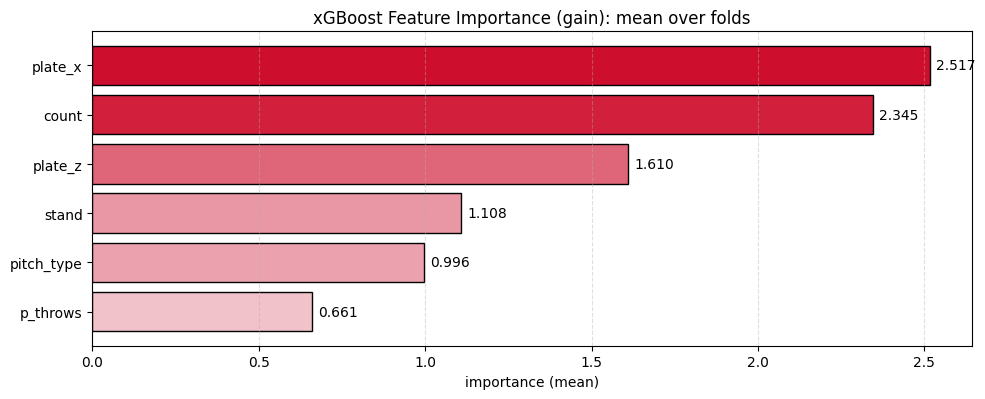

In [ ]:
# 색 설정
BRAND_RED = "#CE0E2D"

def plot_fi_table(fi_df, title):
    # mean 기준 정렬 (전체)
    d = fi_df.sort_values("mean", ascending=False).copy()
    d = d.iloc[::-1]  # barh 보기 좋게

    y = np.arange(len(d))
    means = d["mean"].to_numpy(dtype=float)

    # 값이 클수록 진하게(불투명), 작을수록 연하게(투명)
    vmin, vmax = float(np.min(means)), float(np.max(means))
    if vmax > vmin:
        t = (means - vmin) / (vmax - vmin)  # 0~1
    else:
        t = np.ones_like(means)

    alpha_min, alpha_max = 0.25, 1.0
    alphas = alpha_min + (alpha_max - alpha_min) * t
    base_rgb = mcolors.to_rgb(BRAND_RED)
    bar_colors = [(*base_rgb, float(a)) for a in alphas]

    plt.figure(figsize=(10, max(4, 0.35 * len(d) + 2)))
    plt.barh(
        y, means,
        color=bar_colors,
        edgecolor="black",
        linewidth=1.0
    )

    plt.yticks(y, d.index.tolist())
    plt.xlabel("importance (mean)")
    plt.title(title)
    plt.grid(axis="x", linestyle="--", alpha=0.4)

    # 막대 끝에 값 표기 (소수점 3자리)
    x_pad = (vmax - vmin) * 0.01 if vmax > vmin else 0.01
    for yi, val in zip(y, means):
        plt.annotate(
            f"{val:.3f}",
            xy=(val, yi),
            xytext=(val + x_pad, yi),
            va="center",
            ha="left",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()

# gain만 출력
plot_fi_table(fi_tables["gain"], "xGBoost Feature Importance (gain): mean over folds")

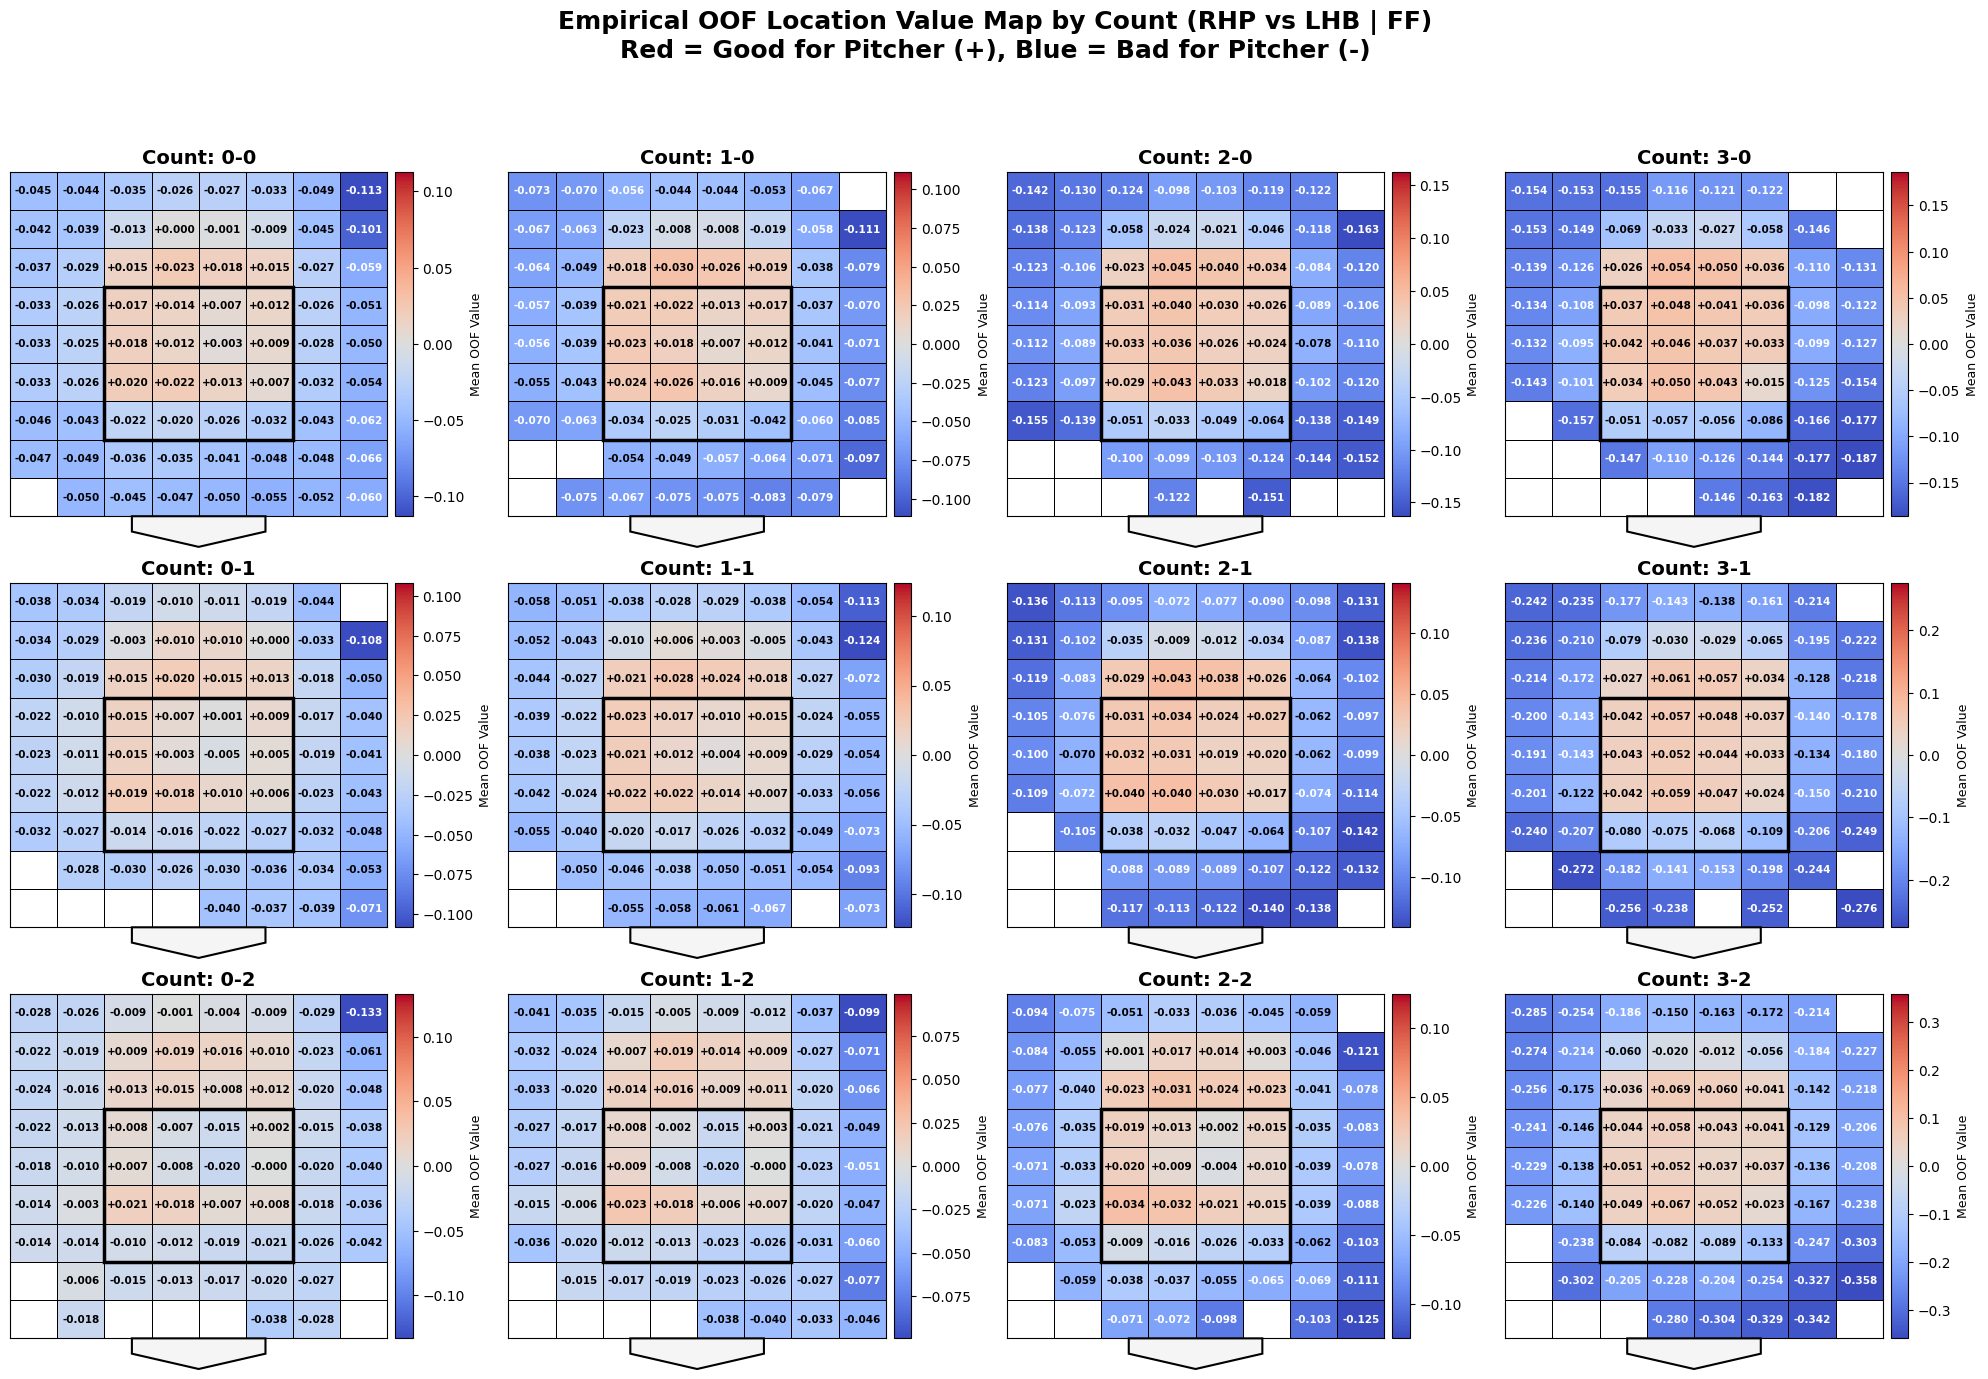

In [ ]:
# Zone Count 기준 Location Value Map 시각화

# 볼스트라이크 조합 목록 정의
all_counts = [
    "0-0", "1-0", "2-0", "3-0",
    "0-1", "1-1", "2-1", "3-1",
    "0-2", "1-2", "2-2", "3-2",
]

# x축 그리드 경계 생성
x_bins = np.linspace(-2, 2, 9)

# z축 그리드 경계 생성
z_bins = np.linspace(0.0, 4.5, 10)

# 각 구간 중심 좌표 생성
x_centers = (x_bins[:-1] + x_bins[1:]) / 2
z_centers = (z_bins[:-1] + z_bins[1:]) / 2

""" 파라미터 설정 파트!"""
pitch_type = "FF"
p_throws = "R"
stand = "L"

# 시각화에 필요한 컬럼 목록 정의
need_cols = ["plate_x", "plate_z", "count", "stand", "p_throws", "pitch_type", "predicted_value_oof"]
missing = [c for c in need_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns in df: {missing}")

# 컨텍스트 조건 필터링
dff = df.loc[
    (df["pitch_type"].astype(str) == pitch_type)
    & (df["p_throws"].astype(str) == p_throws)
    & (df["stand"].astype(str) == stand),
    ["plate_x", "plate_z", "count", "predicted_value_oof"],
].copy()

# x축 구간 인덱스 생성
dff["x_bin"] = pd.cut(dff["plate_x"], bins=x_bins, include_lowest=True, labels=False)

# z축 구간 인덱스 생성
dff["z_bin"] = pd.cut(dff["plate_z"], bins=z_bins, include_lowest=True, labels=False)

# 그리드 밖 좌표 제거
dff = dff.dropna(subset=["x_bin", "z_bin"]).copy()

# 구간 인덱스 정수 변환
dff["x_bin"] = dff["x_bin"].astype(int)
dff["z_bin"] = dff["z_bin"].astype(int)

# 카운트별 타일 평균 맵 저장 딕셔너리 초기화
maps = {}

# 카운트별 타일 평균 맵 생성 반복
for count in all_counts:

    # 카운트별 데이터 선택
    d = dff.loc[dff["count"].astype(str) == count, ["x_bin", "z_bin", "predicted_value_oof"]].copy()

    # 빈 그리드 초기화
    Z = np.full((len(z_centers), len(x_centers)), np.nan, dtype=float)

    # 타일 단위 평균 계산
    g = d.groupby(["z_bin", "x_bin"], as_index=False)["predicted_value_oof"].mean()

    # 타일 평균값 그리드에 반영
    Z[g["z_bin"].to_numpy(), g["x_bin"].to_numpy()] = g["predicted_value_oof"].to_numpy()

    # 카운트별 맵 저장
    maps[count] = Z

# 서브플롯 캔버스 생성
fig, axes = plt.subplots(3, 4, figsize=(20, 14))

# 전체 타이틀 설정
fig.suptitle(
    f"Empirical OOF Location Value Map by Count ({p_throws}HP vs {stand}HB | {pitch_type})\n"
    f"Red = Good for Pitcher (+), Blue = Bad for Pitcher (-)",
    fontsize=18,
    fontweight="bold",
    y=0.98,
)

# 카운트별 히트맵 시각화 반복
for i, count in enumerate(all_counts):

    # 서브플롯 인덱스 계산
    row = i // 4
    col = i % 4
    ax = axes[row, col]

    # 카운트별 타일 평균 맵 로딩
    Z = maps[count]

    # 카운트별 색상 스케일 상하한 계산
    max_abs = float(np.nanmax(np.abs(Z))) if np.isfinite(Z).any() else 0.0
    if max_abs == 0.0:
        max_abs = 1e-9

    # 0 중심 대칭 색상 정규화 객체 생성
    norm = mcolors.TwoSlopeNorm(vmin=-max_abs, vcenter=0.0, vmax=max_abs)

    # 타일 히트맵 시각화
    mesh = ax.pcolormesh(
        x_bins,
        z_bins,
        Z,
        cmap="coolwarm",
        norm=norm,
        edgecolors="black",
        linewidth=0.5,
    )

    # 타일 중앙 값 텍스트 시각화
    for r in range(len(z_centers)):
        for c in range(len(x_centers)):
            val = Z[r, c]
            if np.isfinite(val):
                text_color = "white" if abs(val) > (max_abs * 0.5) else "black"
                ax.text(
                    x_centers[c],
                    z_centers[r],
                    f"{val:+.3f}",
                    ha="center",
                    va="center",
                    color=text_color,
                    fontsize=7.5,
                    fontweight="bold",
                )

    # 스트라이크 존 박스 패치 생성
    sz = patches.Rectangle(
        (-1, 1),
        2.0,
        2.0,
        linewidth=2.5,
        edgecolor="black",
        facecolor="none",
        zorder=3,
    )
    ax.add_patch(sz)

    # 홈플레이트 패치 생성
    home_plate_coords = [
        [-0.708, 0.0],
        [-0.708, -0.2],
        [0.0, -0.4],
        [0.708, -0.2],
        [0.708, 0.0],
    ]
    home_plate = patches.Polygon(
        home_plate_coords,
        closed=True,
        facecolor="whitesmoke",
        edgecolor="black",
        linewidth=1.5,
        clip_on=False,
        zorder=3,
    )
    ax.add_patch(home_plate)

    # 서브플롯 제목 설정
    ax.set_title(f"Count: {count}", fontsize=14, fontweight="bold")

    # 표시 범위 설정
    ax.set_xlim(-2, 2)
    ax.set_ylim(0.0, 4.5)

    # 축 눈금 비표시 설정
    ax.set_xticks([])
    ax.set_yticks([])

    # 서브플롯별 컬러바 추가
    cbar = fig.colorbar(mesh, ax=ax, fraction=0.046, pad=0.02)
    cbar.set_label("Mean OOF Value", fontsize=9)

# 레이아웃 자동 정리 적용
plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.94])

# 시각화 출력
plt.show()

## **Phase 2: KDE를 사용한 히트맵의 수치화**

In [ ]:
# 군집화 없이 KDE만으로 로그 밀도 점수 산출 함수 정의
def apply_pure_kde(g):
    g = g.copy()

    # 로그 밀도 점수 컬럼 초기화
    g["log_density_score"] = np.nan

    # 그룹 표본 수 계산
    n = len(g)

    # 빈 그룹 방어 처리
    if n < 1:
        return g

    # KDE 입력용 좌표 행렬 생성
    coords = np.vstack([g["plate_x"].to_numpy(), g["plate_z"].to_numpy()])

    # 표본 수 부족 시 KDE 생략 처리
    if n < 3:
        return g

    try:
        # Scott 규칙 기반 KDE 객체 생성
        kde = gaussian_kde(coords, bw_method="scott")

        # 관측 좌표 기준 밀도 계산
        densities = kde(coords)

        # 로그 변환 안정화 보정
        densities = np.maximum(densities, np.finfo(float).tiny)

        # 로그 밀도 점수 계산
        g["log_density_score"] = np.log(densities)

    except np.linalg.LinAlgError:
        return g

    except Exception:
        return g

    return g

# 투수 구종 타자손 기준 KDE 적용
df = (
    df.groupby(["player_name", "pitch_type", "stand"], group_keys=False)
      .apply(apply_pure_kde)
)

# KDE 산출값 존재 행 기준 구종 평균 계산
pitch_default = (
    df.loc[df["log_density_score"].notna()]
      .groupby("pitch_type", observed=False)["log_density_score"]
      .mean()
)

# 구종 평균 기준 결측 보정
df["log_density_score"] = df["log_density_score"].fillna(
    df["pitch_type"].map(pitch_default)
)

# 잔여 결측 전체 평균 기준 보정
df["log_density_score"] = df["log_density_score"].fillna(
    df["log_density_score"].mean()
)

# 결과 확인용 출력 컬럼 선택
print(df[["player_name", "pitch_type", "stand", "log_density_score"]].head(10))

/tmp/ipykernel_14522/3546104766.py:45: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["player_name", "pitch_type", "stand"], group_keys=False)
/tmp/ipykernel_14522/3546104766.py:46: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(apply_pure_kde)


           player_name pitch_type stand  log_density_score
2004      Abreu, Bryan         FF     R          -1.875794
2004     Alcala, Jorge         SL     R          -2.291616
2004  Alexander, Tyler         FF     L          -1.349548
2004  Alexander, Tyler         ST     L          -4.822174
2004   Alvarez, Andrew         CU     L          -2.698344
2004   Anderson, Shaun         FF     R          -2.378079
2004      Ashby, Aaron         SI     R          -2.043975
2004      Austin, Cade         CH     R          -2.419857
2004      Bachar, Lake         SL     L          -1.305250
2004     Banks, Tanner         SI     L          -1.307898


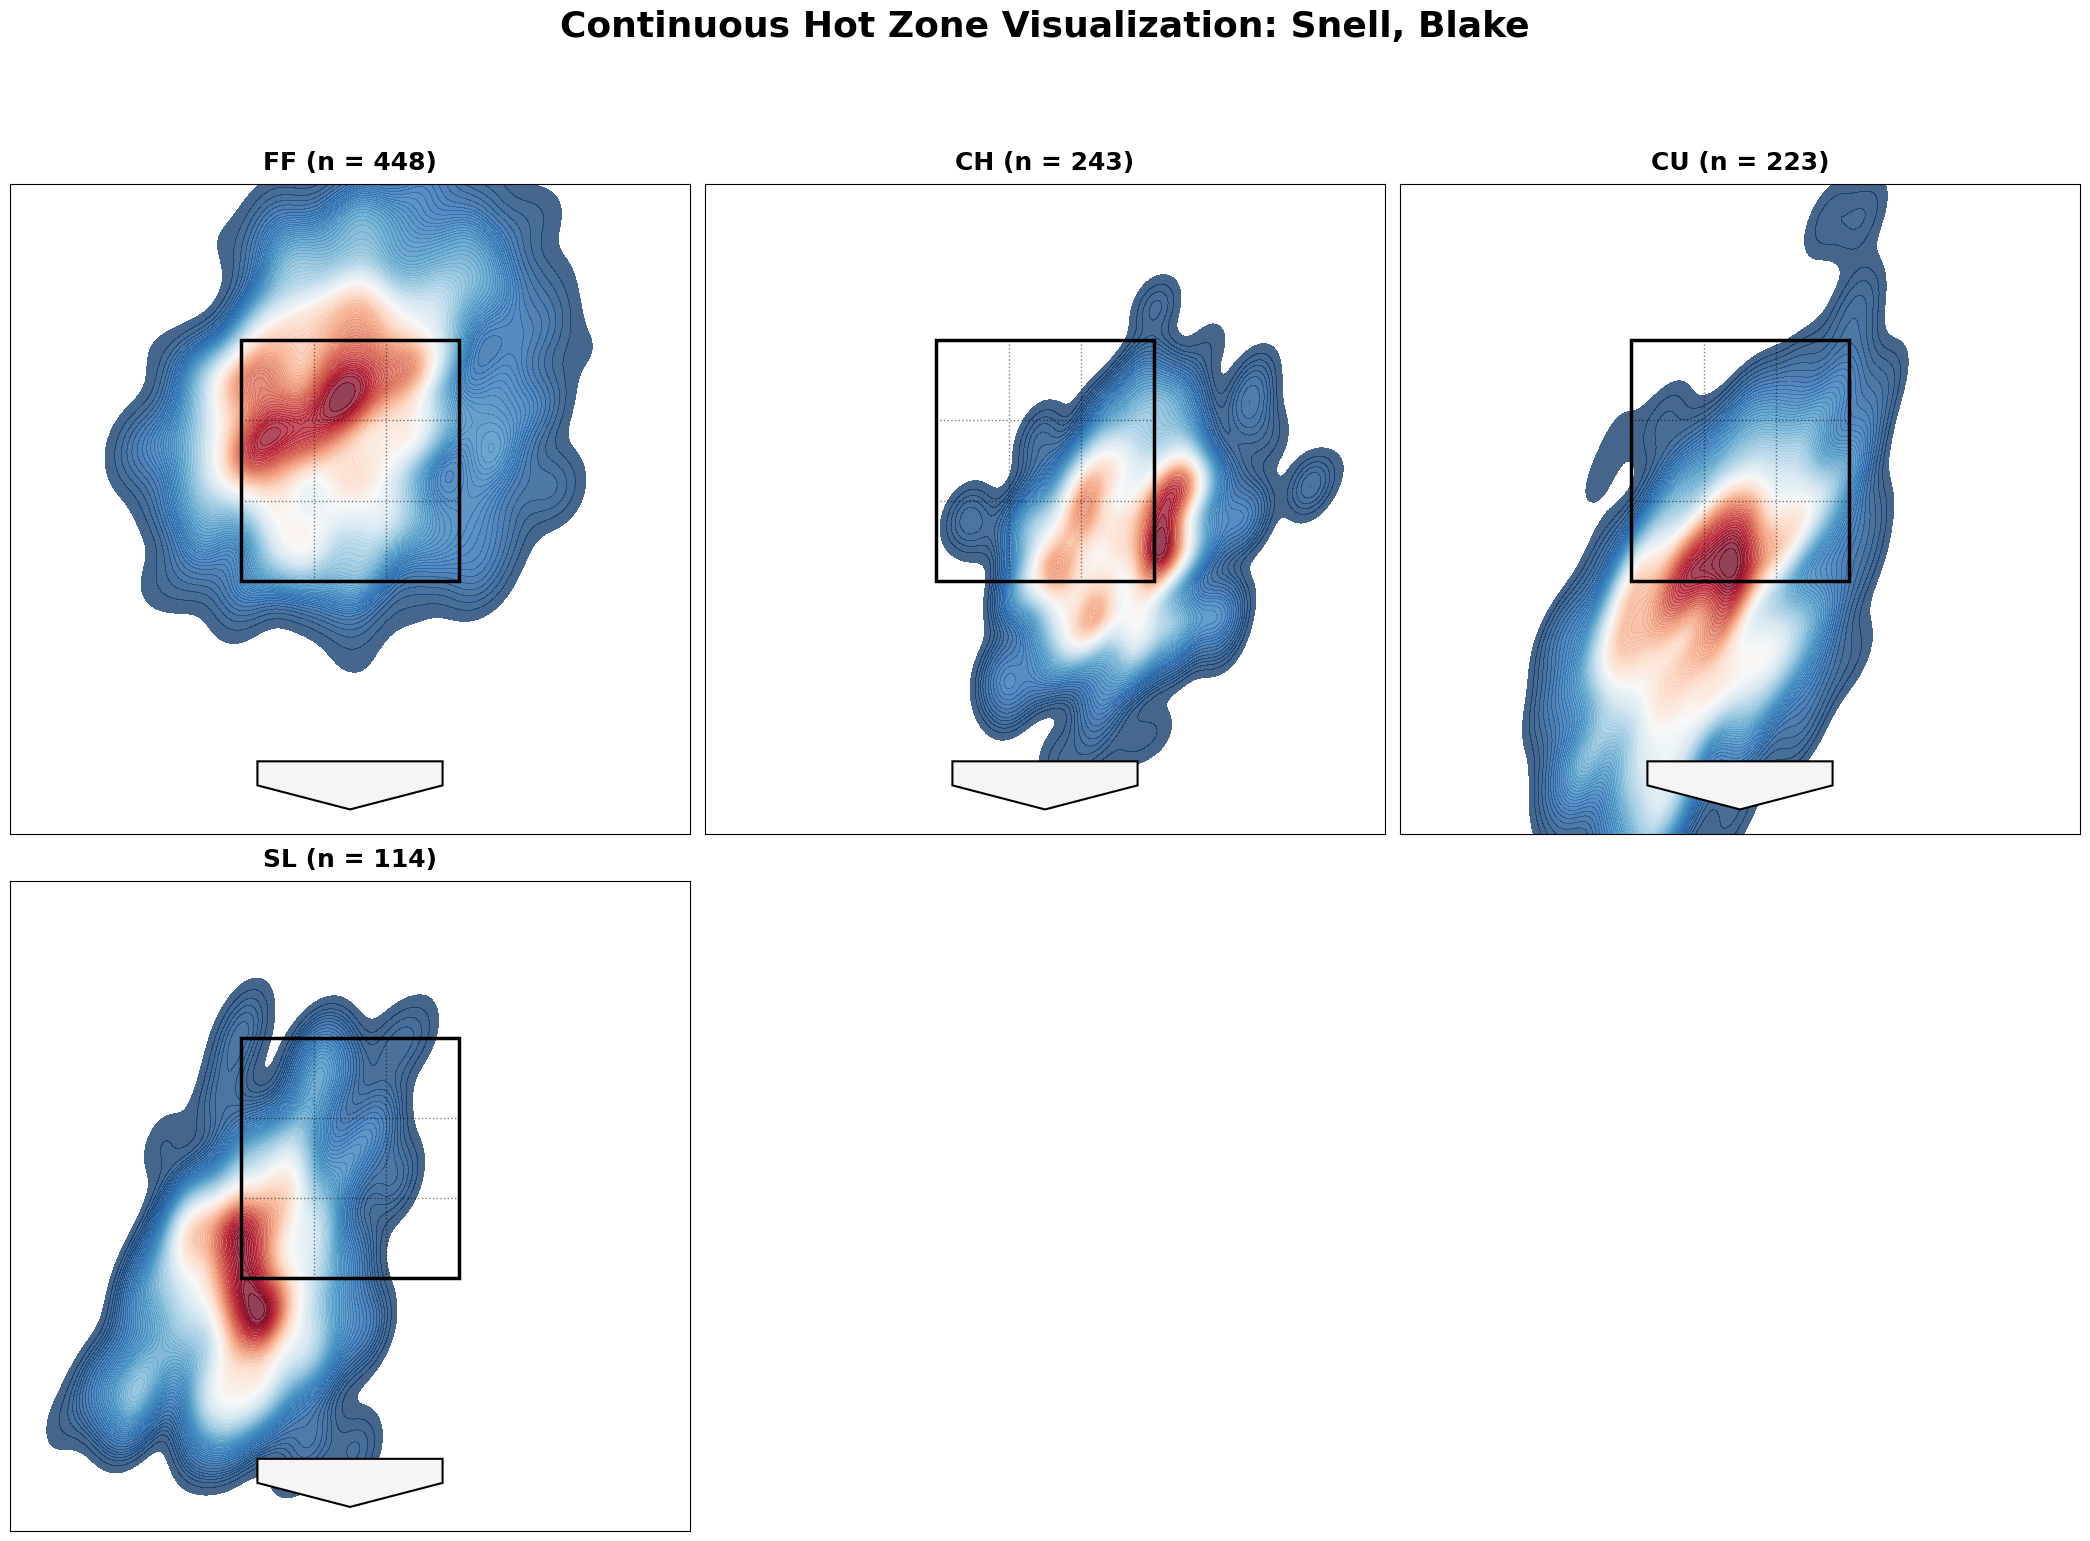

In [ ]:
"""대상 투수명 설정"""
target_pitcher = "Snell, Blake"

# 대상 투수 데이터 추출
pitcher_df = df.loc[df["player_name"] == target_pitcher].copy()

# 실제 투구 기록이 있는 구종만 집계
pitch_counts = pitcher_df["pitch_type"].dropna().value_counts()

# 투구 수 기준 내림차순 구종 목록 생성
pitch_types_sorted = pitch_counts.index.to_numpy()

# 구종 개수 계산
n_pitches = len(pitch_types_sorted)

# 시각화할 구종이 없는 경우 출력 종료
if n_pitches == 0:
    print("No pitches to visualize")
else:
    # 서브플롯 열 개수 설정
    cols = 3

    # 서브플롯 행 개수 계산
    rows = (n_pitches + cols - 1) // cols

    # 서브플롯 크기 확대 설정
    subplot_w = 7
    subplot_h = 7

    # Figure와 Axes 생성
    fig, axes = plt.subplots(rows, cols, figsize=(cols * subplot_w, rows * subplot_h))

    # Axes 1차원 변환
    axes = np.array(axes).ravel()

    # 구종별 시각화 반복
    plot_i = 0
    for pitch_type in pitch_types_sorted:
        # 현재 구종 데이터 추출
        pt_df = pitcher_df.loc[pitcher_df["pitch_type"] == pitch_type].copy()

        # 현재 구종 표본 수 계산
        count = len(pt_df)

        # 표본 수가 1 미만이면 시각화 제외
        if count < 1:
            continue

        # 실제로 그릴 Axes 선택
        ax = axes[plot_i]
        plot_i += 1

        # 로그 점수 기반 가중치 생성
        if "log_density_score" in pt_df.columns:
            s_min = pt_df["log_density_score"].min()
            s_max = pt_df["log_density_score"].max()

            # 히트맵용 가중치 정규화
            if np.isfinite(s_min) and np.isfinite(s_max) and s_max != s_min:
                pt_df["vis_weight"] = (pt_df["log_density_score"] - s_min) / (s_max - s_min) + 0.1
            else:
                pt_df["vis_weight"] = 1.0
        else:
            # 점수 컬럼 부재 대비 기본 가중치 설정
            pt_df["vis_weight"] = 1.0

        # 표본 수가 매우 적을 때 KDE 안정화용 좌표 미세 보정
        if count < 3:
            pt_df["plate_x"] = pt_df["plate_x"].to_numpy() + np.random.normal(0, 0.05, count)
            pt_df["plate_z"] = pt_df["plate_z"].to_numpy() + np.random.normal(0, 0.05, count)

        # 표본 수 기반 KDE 대역폭 조정 값 설정
        bw_val = 0.3 if count <= 20 else 0.7

        # 가중 KDE 히트맵 시각화
        try:
            sns.kdeplot(
                data=pt_df,
                x="plate_x",
                y="plate_z",
                weights="vis_weight",
                fill=True,
                thresh=0.01,
                levels=100,
                cmap="RdBu_r",
                alpha=0.75,
                ax=ax,
                zorder=2,
                bw_adjust=bw_val,
                warn_singular=False
            )
        except Exception:
            pass

        # 스트라이크 존 패치 생성
        strike_zone = patches.Rectangle(
            (-0.83, 1.5),
            1.66,
            2.0,
            linewidth=2.5,
            edgecolor="black",
            facecolor="none",
            zorder=6
        )
        ax.add_patch(strike_zone)

        # 9분할 가이드라인 위치 계산
        h1 = 1.5 + 2.0 / 3
        h2 = 1.5 + 4.0 / 3
        v1 = -0.83 + 1.66 / 3
        v2 = -0.83 + 3.32 / 3

        # 9분할 가이드라인 시각화
        ax.plot([-0.83, 0.83], [h1, h1], color="black", linestyle=":", linewidth=1, alpha=0.5, zorder=6)
        ax.plot([-0.83, 0.83], [h2, h2], color="black", linestyle=":", linewidth=1, alpha=0.5, zorder=6)
        ax.plot([v1, v1], [1.5, 3.5], color="black", linestyle=":", linewidth=1, alpha=0.5, zorder=6)
        ax.plot([v2, v2], [1.5, 3.5], color="black", linestyle=":", linewidth=1, alpha=0.5, zorder=6)

        # 홈플레이트 패치 생성
        home_plate = patches.Polygon(
            [[-0.708, 0], [-0.708, -0.2], [0, -0.4], [0.708, -0.2], [0.708, 0]],
            closed=True,
            facecolor="whitesmoke",
            edgecolor="black",
            linewidth=1.5,
            zorder=6,
            clip_on=False
        )
        ax.add_patch(home_plate)

        # 서브플롯 제목 설정
        ax.set_title(f"{pitch_type} (n = {count})", fontsize=18, fontweight="bold", pad=10)

        # 축 범위 확대 설정
        ax.set_xlim(-2.6, 2.6)
        ax.set_ylim(-0.6, 4.8)

        # 축 라벨 제거
        ax.set_xlabel("")
        ax.set_ylabel("")

        # 축 눈금 제거
        ax.set_xticks([])
        ax.set_yticks([])

        # 그리드 비활성화
        ax.grid(False)

    # 실제로 그린 개수 이후의 빈 서브플롯 제거
    for j in range(plot_i, len(axes)):
        fig.delaxes(axes[j])

    # 레이아웃 조정
    plt.tight_layout()

    # 전체 타이틀 설정
    fig.suptitle(
        f"Continuous Hot Zone Visualization: {target_pitcher}",
        fontsize=26,
        fontweight="bold",
        y=1.03
    )

    # 결과 출력
    plt.show()

In [ ]:
# pitch_type 기준 그룹별 log_density_score 평균과 표준편차 계산
stats_by_pitch = (
    df.groupby("pitch_type")["log_density_score"]
      .agg(["mean", "std"])
      .reset_index()
      .rename(columns={"mean": "pitch_mean", "std": "pitch_std"})
)

# 구종별 통계치를 원본 데이터프레임에 결합
df = df.merge(stats_by_pitch, on="pitch_type", how="left")

# 구종별 평균과 표준편차 기준 Z score 컬럼 생성
df["z_score_by_pitch"] = np.where(
    df["pitch_std"].fillna(0) == 0,  # 평균치로 처리
    0,
    (df["log_density_score"] - df["pitch_mean"]) / df["pitch_std"]
)

# 결합 과정에서 생성된 임시 통계 컬럼 제거
df.drop(columns=["pitch_mean", "pitch_std"], inplace=True)

# 결과 확인용 출력 컬럼 선택
print(df[["player_name", "pitch_type", "log_density_score", "z_score_by_pitch"]].head())

/tmp/ipykernel_14522/1810016755.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("pitch_type")["log_density_score"]


        player_name pitch_type  log_density_score  z_score_by_pitch
0      Abreu, Bryan         FF          -1.875794          0.305762
1     Alcala, Jorge         SL          -2.291616         -0.272453
2  Alexander, Tyler         FF          -1.349548          0.994534
3  Alexander, Tyler         ST          -4.822174         -3.658503
4   Alvarez, Andrew         CU          -2.698344         -0.639657


/tmp/ipykernel_14522/4076046233.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


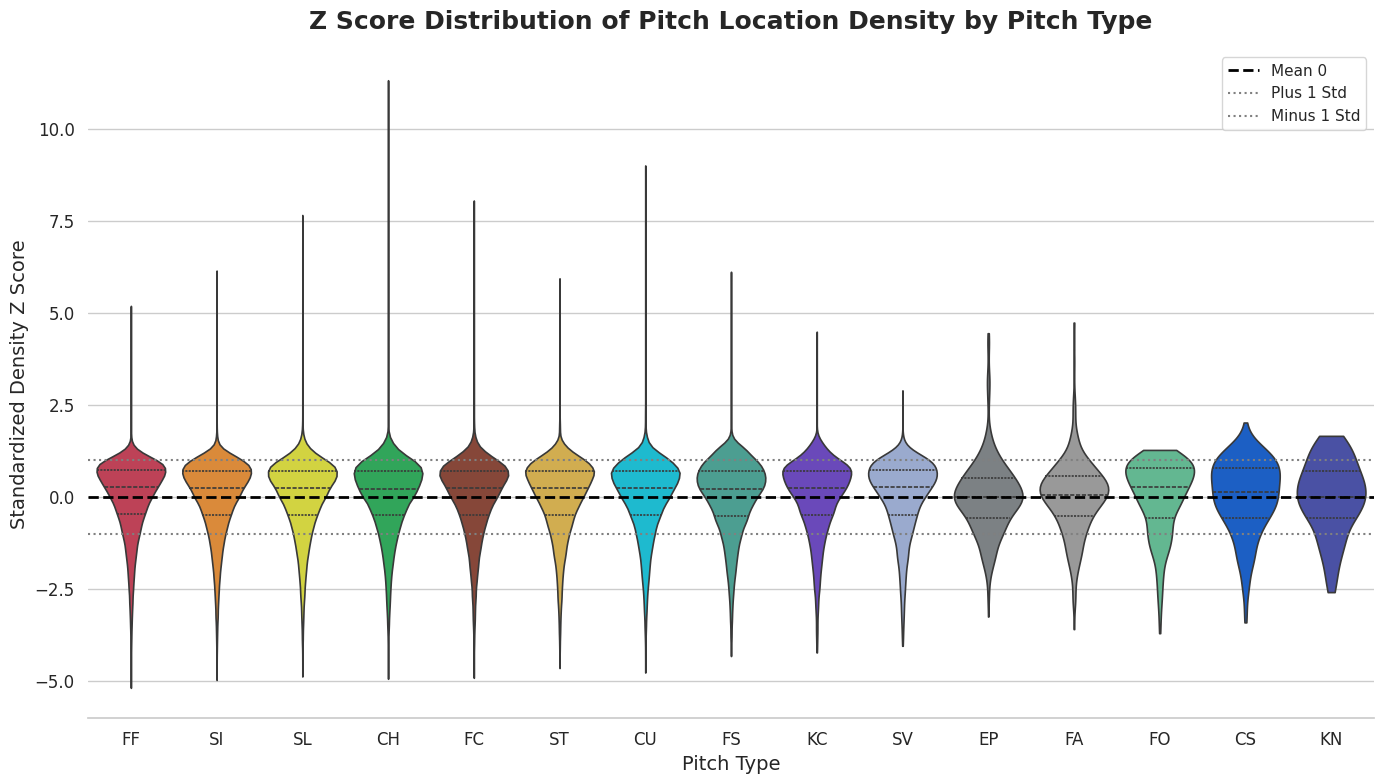

In [ ]:
# Baseball Savant 기준 구종 색상 매핑 딕셔너리 정의
savant_colors = {
    "FF": "#D22D49",
    "SI": "#F58A1F",
    "FC": "#933F2C",
    "CH": "#1DB954",
    "FS": "#3EAC9A",
    "FO": "#55C592",
    "SC": "#54C93F",
    "CU": "#00D1ED",
    "KC": "#6236CD",
    "CS": "#005AE0",
    "SL": "#EAEB29",
    "ST": "#E7B73A",
    "SV": "#92A7D6",
    "KN": "#3B44B3",
    "EP": "#7B8185",
    "FA": "#999999",
    "IN": "#999999",
    "PO": "#999999"
}

# pitch_type 컬럼 기준 구종별 투구 수 집계
pitch_counts = df["pitch_type"].value_counts()

# 최소 투구 수 기준 초과 구종 코드 목록 생성
valid_pitches = pitch_counts[pitch_counts > 100].index

# 시각화 대상 행 필터링 후 독립 데이터프레임 생성
plot_df = df[df["pitch_type"].isin(valid_pitches)].copy()

# 시각화 캔버스 크기 설정
plt.figure(figsize=(14, 8))

# Seaborn 테마 설정
sns.set_theme(style="whitegrid")

# 구종 순서 고정용 리스트 생성
pitch_order = list(valid_pitches)

# 시각화 대상 구종에 해당하는 팔레트 딕셔너리 생성
palette_map = {p: savant_colors.get(p, "#999999") for p in pitch_order}

# 구종별 density_z 분포 바이올린 플롯 시각화
sns.violinplot(
    data=plot_df,
    x="pitch_type",
    y="z_score_by_pitch",
    order=pitch_order,
    palette=palette_map,
    inner="quartile",
    linewidth=1.2,
    cut=0
)

# 기준선 0 표시
plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Mean 0"
)

# 기준선 1 표시
plt.axhline(
    y=1.0,
    color="gray",
    linestyle=":",
    linewidth=1.5,
    label="Plus 1 Std"
)

# 기준선 마이너스 1 표시
plt.axhline(
    y=-1.0,
    color="gray",
    linestyle=":",
    linewidth=1.5,
    label="Minus 1 Std"
)

# 그래프 제목 설정
plt.title(
    "Z Score Distribution of Pitch Location Density by Pitch Type",
    fontsize=18,
    fontweight="bold",
    pad=15
)

# x축 라벨 설정
plt.xlabel("Pitch Type", fontsize=14)

# y축 라벨 설정
plt.ylabel("Standardized Density Z Score", fontsize=14)

# x축 눈금 글자 크기 설정
plt.xticks(fontsize=12)

# y축 눈금 글자 크기 설정
plt.yticks(fontsize=12)

# 범례 표시
plt.legend(loc="upper right")

# 좌측 테두리 제거
sns.despine(left=True)

# 레이아웃 여백 자동 보정
plt.tight_layout()

# 그래프 출력
plt.show()

## **Phase 3: 안정화 시점 판정 및 수치 정규화**

/tmp/ipykernel_14522/1307089005.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_stab["pitch_seq"] = df_stab.groupby(["player_name", "pitch_type"]).cumcount()


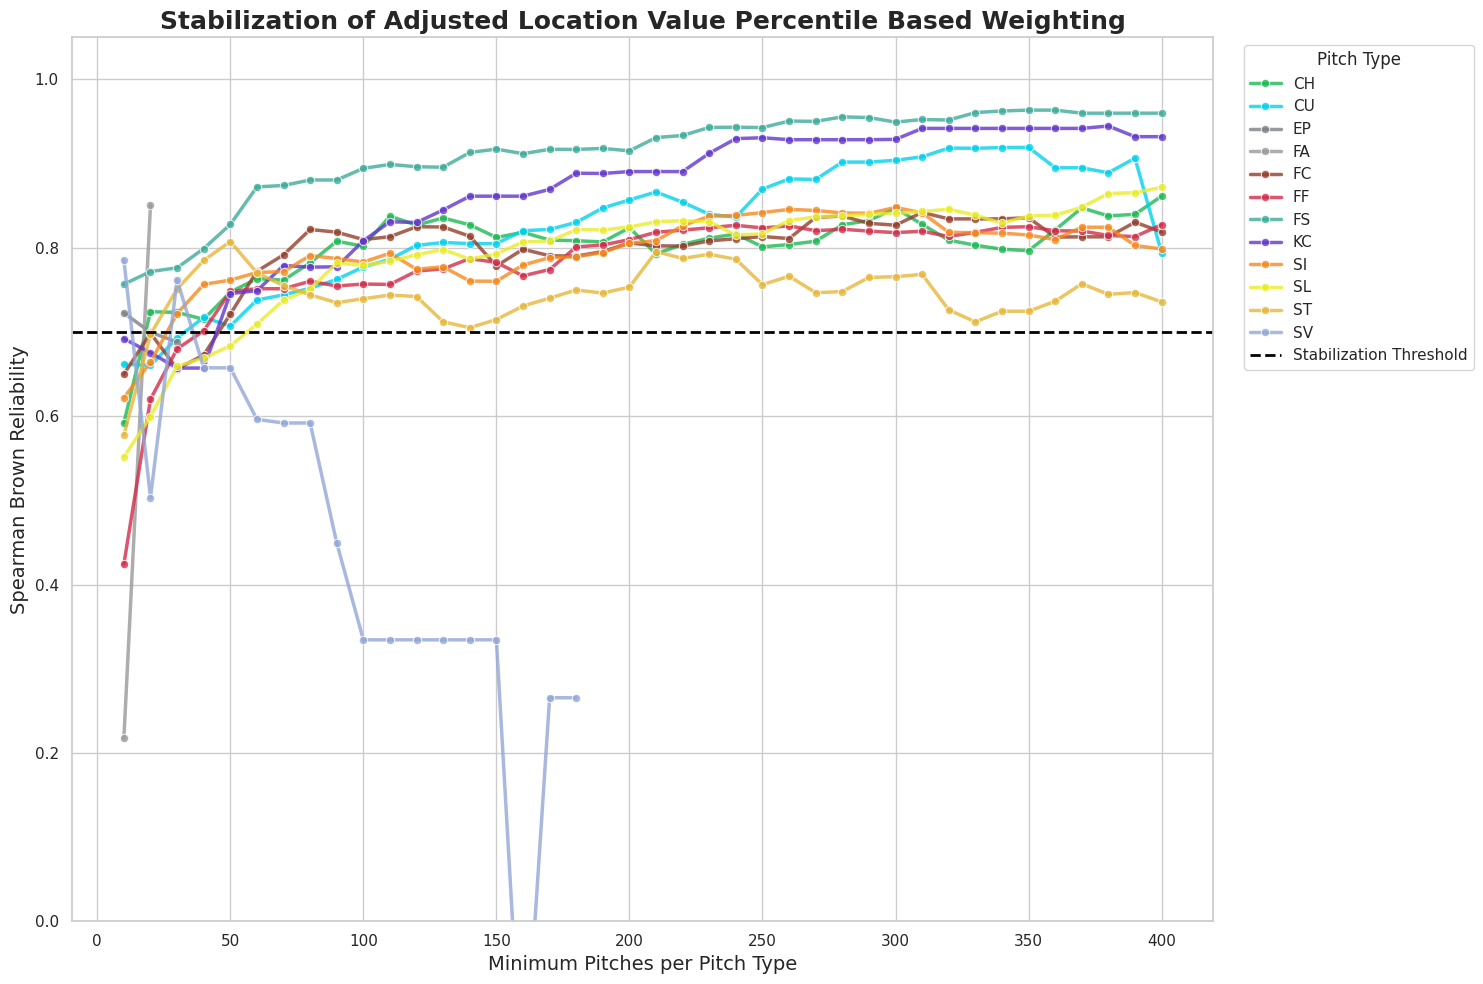

In [ ]:
# 일관성 백분위 컬럼 생성
df["consistency_percentile"] = stats_norm.cdf(df["z_score_by_pitch"])

# 백분위 기반 위치 가중치 컬럼 생성
df["location_weight"] = (df["consistency_percentile"] * 2)

# 위치 가중치 범위 제한
df["location_weight"] = df["location_weight"].clip(0.1, 2.0)

# 가중 위치 가치 컬럼 생성
df["location_run_value"] = df["predicted_value_oof"] * df["location_weight"]

# 원본 보존용 복사본 생성
df_stab = df.copy()

# 투수 구종 단위 투구 순번 컬럼 생성
df_stab["pitch_seq"] = df_stab.groupby(["player_name", "pitch_type"]).cumcount()

# 투구 순번 기반 반분 구분 컬럼 생성
df_stab["split_half"] = np.where(df_stab["pitch_seq"] % 2 == 0, "even", "odd")

# 반분 그룹별 location_run_value 평균 집계
split_stats = (
    df_stab
    .groupby(["player_name", "pitch_type", "split_half"], observed=False)["location_run_value"]
    .mean()
    .unstack()
    .reset_index()
)

# 투수 구종 단위 총 투구 수 집계
pitch_counts = (
    df_stab
    .groupby(["player_name", "pitch_type"], observed=False)
    .size()
    .reset_index(name="total_pitches")
)

# 투구 수 결합 및 even odd 결측 제거
split_stats = (
    split_stats
    .merge(pitch_counts, on=["player_name", "pitch_type"], how="left")
    .dropna(subset=["even", "odd"])
)

# 구종 목록 생성
target_pitches = split_stats["pitch_type"].dropna().unique().tolist()

# 최소 투구 수 기준 범위 생성
thresholds = range(10, 410, 10)

# 결과 저장 리스트 초기화
results = []

# 구종별 최소 투구 수 기준 신뢰도 계산
for pt in target_pitches:
    df_pt = split_stats[split_stats["pitch_type"] == pt]
    for t in thresholds:
        subset = df_pt[df_pt["total_pitches"] >= t]
        if len(subset) < 8:
            continue

        r, _ = stats.pearsonr(subset["even"], subset["odd"])
        R = (2 * r) / (1 + r) if (1 + r) != 0 else 0
        results.append({"pitch_type": pt, "min_pitches": t, "reliability_R": R})

# 신뢰도 결과 데이터프레임 생성
stab_df = pd.DataFrame(results)

# 시각화 구종 순서 생성
pitch_order = sorted(stab_df["pitch_type"].unique().tolist())

# 시각화 팔레트 딕셔너리 생성
palette_map = {p: savant_colors.get(p, "#999999") for p in pitch_order}

# 시각화 캔버스 크기 설정
plt.figure(figsize=(15, 10))

# Seaborn 테마 설정
sns.set_theme(style="whitegrid")

# 구종별 신뢰도 라인 플롯 생성
sns.lineplot(
    data=stab_df,
    x="min_pitches",
    y="reliability_R",
    hue="pitch_type",
    hue_order=pitch_order,
    palette=palette_map,
    marker="o",
    linewidth=2.5,
    alpha=0.8
)

# 안정화 기준선 표시
plt.axhline(
    y=0.7,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Stabilization Threshold"
)

# 그래프 제목 텍스트 설정
plt.title(
    "Stabilization of Adjusted Location Value Percentile Based Weighting",
    fontsize=18,
    fontweight="bold"
)

# x축 라벨 텍스트 설정
plt.xlabel("Minimum Pitches per Pitch Type", fontsize=14)

# y축 라벨 텍스트 설정
plt.ylabel("Spearman Brown Reliability", fontsize=14)

# y축 표시 범위 설정
plt.ylim(0, 1.05)

# 범례 위치와 제목 설정
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Pitch Type")

# 레이아웃 여백 자동 보정
plt.tight_layout()

# 그래프 출력
plt.show()

In [ ]:
# 안정 구종 판정용 최소 투구 수 기준 설정
min_stab_pitches = 60

# pitch_type 결측 제거 후 투수 구종 단위 투구 수 집계
player_pitch_counts = (
    df.dropna(subset=["pitch_type"])
    .groupby(["player_name", "pitch_type"], observed=True)
    .size()
    .reset_index(name="pitch_count")
)

# 투수별 전체 구종 개수 집계
pitcher_total_types = (
    player_pitch_counts
    .groupby("player_name", observed=True)["pitch_type"]
    .nunique()
    .reset_index(name="total_types")
)

# 투수별 안정 구종 개수 집계
pitcher_stable_types = (
    player_pitch_counts
    .assign(is_stable=player_pitch_counts["pitch_count"] >= min_stab_pitches)
    .groupby("player_name", observed=True)["is_stable"]
    .sum()
    .reset_index(name="stable_types")
)

# 투수별 구종 구성 요약 결합
pitcher_coverage = pitcher_total_types.merge(pitcher_stable_types, on="player_name", how="left")

# 안정 구종 개수 결측 보정
pitcher_coverage["stable_types"] = pitcher_coverage["stable_types"].fillna(0).astype(int)

# 커버리지 비율 계산
pitcher_coverage["coverage_ratio"] = pitcher_coverage["stable_types"] / pitcher_coverage["total_types"]

# 커버리지 기준 합격 투수 목록 추출
valid_pitchers = pitcher_coverage.loc[pitcher_coverage["coverage_ratio"] >= 0.5, "player_name"].unique()

# 합격 투수 데이터 필터링
df_valid = df[df["player_name"].isin(valid_pitchers)].copy()

# pitch_type 결측 제거
df_valid = df_valid.dropna(subset=["pitch_type"])

# 투수 구종 단위 location_run_value 투구 수와 평균 집계
player_pitch_rv = (
    df_valid
    .groupby(["player_name", "pitch_type"], observed=True)
    .agg(
        pitch_count=("location_run_value", "count"),
        rv_mean=("location_run_value", "mean")
    )
    .reset_index()
)

# 안정 구종만 남기는 필터링
player_pitch_rv = player_pitch_rv[player_pitch_rv["pitch_count"] >= min_stab_pitches].copy()

# 리그 평균 산출용 가중 합계 컬럼 생성
player_pitch_rv["total_rv"] = player_pitch_rv["rv_mean"] * player_pitch_rv["pitch_count"]

# 구종별 리그 평균 위치 가치 계산
league_avg = (
    player_pitch_rv
    .groupby("pitch_type", observed=True)[["total_rv", "pitch_count"]]
    .sum()
    .reset_index()
)

# 구종별 리그 평균 위치 가치 컬럼 생성
league_avg["league_rv_mean"] = league_avg["total_rv"] / league_avg["pitch_count"]

# 리그 평균 컬럼만 유지
league_avg = league_avg[["pitch_type", "league_rv_mean"]]

# 구종별 리그 평균 결합
df_q = player_pitch_rv.merge(league_avg, on="pitch_type", how="left")

# 구종별 리그 평균 대비 가치 계산
df_q["rv_above_avg"] = df_q["rv_mean"] - df_q["league_rv_mean"]

# 투수별 가중 합계 계산용 컬럼 생성
df_q["weighted_val_sum"] = df_q["rv_above_avg"] * df_q["pitch_count"]

# 투수별 가중 평균 산출용 집계
player_final = (
    df_q
    .groupby("player_name", observed=True)
    .agg(
        total_pitches=("pitch_count", "sum"),
        total_weighted_val=("weighted_val_sum", "sum")
    )
    .reset_index()
)

# 투수별 가중 평균 리그 평균 대비 위치 가치 계산
player_final["weighted_rv_above_avg"] = player_final["total_weighted_val"] / player_final["total_pitches"]

# 순위 기반 누적확률 계산용 표본 수 산출
n_players = len(player_final)

# 순위 기반 누적확률 컬럼 생성
player_final["rank_p"] = (
    player_final["weighted_rv_above_avg"]
    .rank(method="average", ascending=True)
    .sub(0.5)
    .div(n_players)
)

# 누적확률 범위 보정
player_final["rank_p"] = player_final["rank_p"].clip(1e-6, 1 - 1e-6)

# 정규분포 분위수 기반 z 점수 컬럼 생성
player_final["z_norm"] = stats_norm.ppf(player_final["rank_p"])

# 정규분포 기반 원점수 컬럼 생성
player_final["raw_location+"] = 50 + 10 * player_final["z_norm"]

# 오 단위 반올림 점수 생성
player_final["location+"] = (player_final["raw_location+"] / 5).round() * 5

# 점수 범위 제한
player_final["location+"] = player_final["location+"].clip(20, 80).astype(int)

# 임시 컬럼 제거
player_final.drop(columns=["rank_p", "z_norm"], inplace=True)

# 최종 리더보드 생성
df_location_master = (
    player_final[["player_name", "total_pitches", "weighted_rv_above_avg", "location+"]]
    .sort_values(by=["location+", "weighted_rv_above_avg"], ascending=False)
    .copy()
)

# 리더보드 상위 출력
df_location_master.head(50)

,player_name,total_pitches,weighted_rv_above_avg,location+
323,"Mahle, Tyler",1506,0.005621,80
336,"Matz, Steven",1217,0.005056,80
354,"Messick, Parker",625,0.005003,75
115,"Cox, Austin",366,0.004710,75
574,"Williams, Trevor",1448,0.004707,75
125,"De Los Santos, Enyel",1105,0.004525,75
362,"Milner, Hoby",1179,0.004516,75
147,"Eovaldi, Nathan",1896,0.004479,70
265,"Johnson, Ryan",281,0.004474,70
394,"Ohl, Pierson",507,0.004340,70


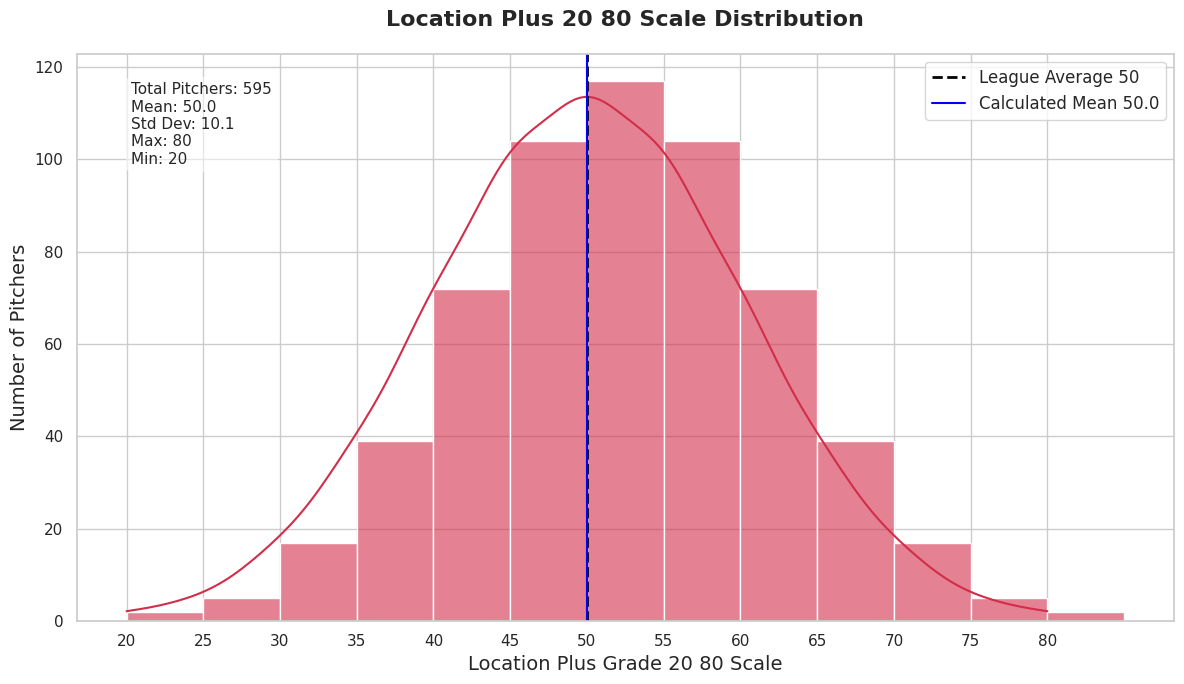

In [ ]:
# 시각화 캔버스 크기 설정
plt.figure(figsize=(12, 7))

# Seaborn 스타일 설정
sns.set_theme(style="whitegrid")

# 히스토그램 및 KDE 시각화
sns.histplot(
    df_location_master["location+"],
    bins=range(20, 86, 5),
    kde=True,
    color="#D22D49",
    alpha=0.6,
    edgecolor="white"
)

# 리그 평균 기준선 표시
plt.axvline(50, color="black", linestyle="--", linewidth=2, label="League Average 50")


# 실제 계산된 평균 산출
actual_mean = df_location_master["location+"].mean()

# 실제 평균 기준선 표시
plt.axvline(actual_mean, color="blue", linestyle="-", linewidth=1.5,
            label=f"Calculated Mean {actual_mean:.1f}")

# 제목 설정
plt.title("Location Plus 20 80 Scale Distribution", fontsize=16, fontweight="bold", pad=20)

# x축 라벨 설정
plt.xlabel("Location Plus Grade 20 80 Scale", fontsize=14)

# y축 라벨 설정
plt.ylabel("Number of Pitchers", fontsize=14)

# x축 눈금 설정
plt.xticks(range(20, 85, 5))

# 범례 표시
plt.legend(fontsize=12)

# 통계 요약값 산출
std_val = df_location_master["location+"].std()
max_val = df_location_master["location+"].max()
min_val = df_location_master["location+"].min()
total_pitchers = len(df_location_master)

# 통계 텍스트 구성
stats_text = (
    f"Total Pitchers: {total_pitchers}\n"
    f"Mean: {actual_mean:.1f}\n"
    f"Std Dev: {std_val:.1f}\n"
    f"Max: {max_val}\n"
    f"Min: {min_val}"
)

# 텍스트 박스 추가
plt.gca().text(
    0.05,
    0.95,
    stats_text,
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.5)
)

# 레이아웃 보정
plt.tight_layout()

# 그래프 출력
plt.show()

In [ ]:
# 정규성 진단 대상 컬럼 선택
data = df_location_master["location+"].dropna()

# 표본 수 산출
n = int(data.shape[0])

# 왜도 산출
skew_val = float(skew(data))

# 첨도 산출
kurt_val = float(kurtosis(data))

print(f"표본 수 {n}")
print(f"왜도 {skew_val:.3f}")
print(f"첨도 {kurt_val:.3f}")

# D Agostino K squared 정규성 검정 통계량 산출
stat, p_value = normaltest(data)

print(f"D Agostino K squared p value {p_value:.4e}")

표본 수 595
왜도 0.000
첨도 -0.067
D Agostino K squared p value 5.9144e-01


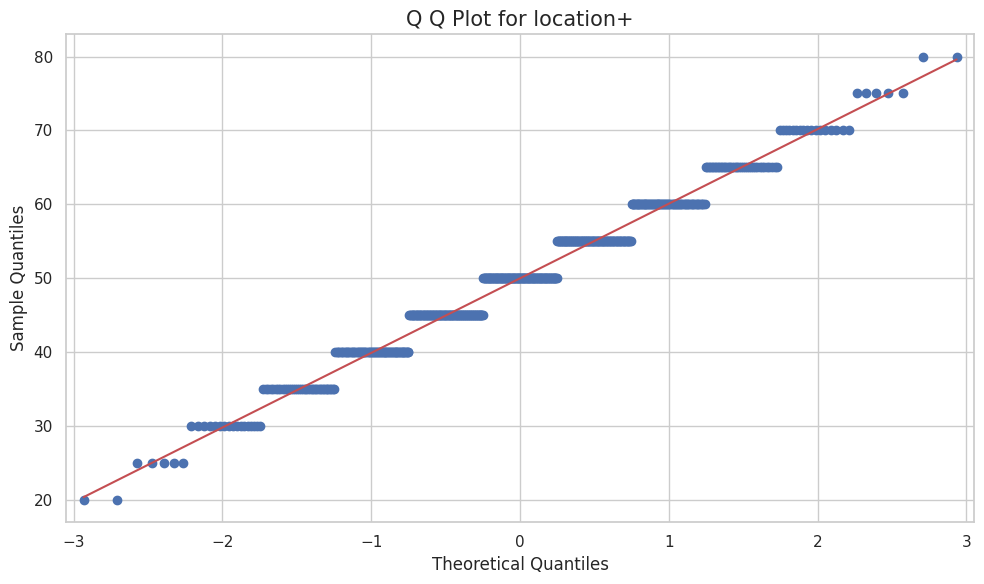

In [ ]:
# Q Q Plot 캔버스 크기 설정
plt.figure(figsize=(10, 6))

# Q Q Plot 시각화
sm.qqplot(data, line="s", ax=plt.gca())

# 제목 설정
plt.title("Q Q Plot for location+", fontsize=15)

# 레이아웃 보정
plt.tight_layout()

# 그래프 출력
plt.show()